# Lab 3: Robot Control

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/LxViRaL-teaching/medical-robotics-2026/blob/main/week-3/control_lab.ipynb)

In this lab you control the motion of robots using feedback: This is done in a loop that reads the sensors, computes a torque for each motor, and sends it, hundreds of times per second.
Besides this notebook there are three auxiliary files:

| File | What it is |
|---|---|
| `pendulum.urdf` | The motorised pendulum. The angle is 0 when it hangs straight down. Its masses are listed at the top of the file. |
| `arm_2r.urdf` | A planar 2-link arm with a 4 kg payload at the tip. |
| `ctrl_utils.py` | Helpers to load robots and draw plots. You do not need to edit it. |

First, let's check the environment and do the relevant imports:

In [1]:
import os, sys, time, urllib.request

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    import subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pybullet"], check=True)
    RAW = "https://raw.githubusercontent.com/LxViRaL-teaching/medical-robotics-2026/main/week-3/"
    for f in ["ctrl_utils.py", "pendulum.urdf", "arm_2r.urdf"]:
        if not os.path.exists(f):
            urllib.request.urlretrieve(RAW + f, f)

import numpy as np
import pybullet as p
import ctrl_utils as ctl

import pandas as pd
import matplotlib.pyplot as plt

DT = ctl.DT   # time step of the simulation, and of our controller: 1/240 s

In [8]:
%pip install pandas

   ---------------------------------------- 0.0/11.0 MB ? eta -:--:--
   - -------------------------------------- 0.5/11.0 MB 3.4 MB/s eta 0:00:04
   -- ------------------------------------- 0.8/11.0 MB 3.0 MB/s eta 0:00:04
   ---- ----------------------------------- 1.3/11.0 MB 2.2 MB/s eta 0:00:05
   ------- -------------------------------- 2.1/11.0 MB 2.8 MB/s eta 0:00:04
   ---------- ----------------------------- 2.9/11.0 MB 2.8 MB/s eta 0:00:03
   ------------- -------------------------- 3.7/11.0 MB 3.0 MB/s eta 0:00:03
   --------------- ------------------------ 4.2/11.0 MB 3.0 MB/s eta 0:00:03
   ------------------- -------------------- 5.2/11.0 MB 3.2 MB/s eta 0:00:02
   -------------------- ------------------- 5.5/11.0 MB 3.1 MB/s eta 0:00:02
   ------------------------ --------------- 6.8/11.0 MB 3.3 MB/s eta 0:00:02
   --------------------------- ------------ 7.6/11.0 MB 3.4 MB/s eta 0:00:02
   ----------------------------- ---------- 8.1/11.0 MB 3.4 MB/s eta 0:00:01
   ---

In [2]:
DT 

0.004166666666666667

## Declaration of AI Use

AI tools were used during the generation of this notebook for coding support, language refinement and for tutoring purposes. However, the results presented are primarily the author's own work, unless stated otherwise.

## 1. The pendulum

`ctl.load_robot` loads the robot with its default motor controllers switched off: from now on, the only torque on the joint is the one you send.

In [3]:
ctl.connect()
pendulum = ctl.load_robot("pendulum.urdf")
motor = ctl.joint_index(pendulum, "motor_joint")
ball = ctl.link_index(pendulum, "ball_link")

In [4]:
ctl.reset_joints(pendulum, [motor], [np.pi/2])
t = 0.0
duration = 6.0
time_log, angle_log, torque_log = [], [], []

p.enableJointForceTorqueSensor(pendulum,motor,1)
while t < duration:

    p.stepSimulation()
    q,qd,tau,_ = p.getJointState(pendulum, motor)

    t = t + DT
    time.sleep(DT)

    # Logging:
    time_log.append(t)
    angle_log.append(q)

ctl.plot_series(time_log, {"Joint Position": angle_log}, ylabel="angle [rad]")

### 1.1 Proportional control

The goal is to lift the arm to the horizontal, $q_{desired} = \pi/2$. We set motor torque to be proportional to the current error:

$$\tau = K_p\,(q_{desired} - q)$$

> **T1.** Find a reasonable value for $K_p$ and implement a P control law

In [5]:
# DETOUR: ALTERED CODE TO FIND K_p
# accepted threshold for error ~ 1 degree

run_cell = False             # set to True to run the cell, False to skip it
                             # takes around 20 minutes to execute

if run_cell:   

    # Controller settings
    q_desired = np.pi / 2    # target angle [rad]: arm horizontal
    Kp = 6.0                 # proportional gain [N m per rad of error] #TODO: 
    duration = 15.0          # how long to run [s]

    # add ons
    success = False
    threshold = 0.02         # accepted error threshold [rad] - 0.02 rad ~ 1 degree
    Kp_log = [Kp]            # log of Kp values
    error_log = []           # log of error values


    while success == False:
        
        # Start with the arm hanging down, at rest
        ctl.reset_joints(pendulum, [motor], [0.0])

        time_log, angle_log, torque_log = [], [], []
        t = 0.0

        while t < duration:

            # check after 1 second if the arm has reached the desired position, if not increase Kp
            if t >= 1.0 and t <= 1.0 + DT:
                if max(angle_log) >= np.pi/2:
                    print('here, angle log max: ', max(angle_log))
                    pass
                else:       
                    Kp = Kp + 5.0
                    print("Increasing Kp to: ", Kp)
                    Kp_log.append(Kp)
                    error_log.append(error)  # for old error (1 entry behind Kp_log)
                    break

            # 1. SENSE: read the joint angle from the encoder
            q = p.getJointState(pendulum, motor)[0]

            # 2. CONTROL: compute the motor torque from the error
            error = q_desired - q
            torque = Kp * error

            # 3. ACT: send the torque to the motor, and let the simulated world move for one time step
            p.setJointMotorControl2(pendulum, motor, p.TORQUE_CONTROL, force=torque)

            
            # 4. WAIT: let one time step of real time pass, so what you see runs at real speed (comment out for faster simulation, or sleep for DT/4)
            p.stepSimulation()
            t = t + DT
            
            time.sleep(DT)

            # Logging:
            time_log.append(t)
            angle_log.append(q)
            torque_log.append(torque)

            # break if the error is below the threshold

            # check after 1 second if the arm has reached the desired position, if not increase Kp
            if t >= duration - 3*DT and t <= duration - 2*DT:
                error_mean = np.mean(np.array(angle_log[-20:]) - q_desired)
                if abs(error_mean) < threshold:
                    error_log.append(error)
                    success = True
                    break
                else:
                    Kp = Kp - Kp*error_mean*0.5
                    Kp_log.append(Kp)
                    error_log.append(error)

                    print("Changing Kp to: ", Kp)
            

    p_time, p_angle, p_torque = time_log, angle_log, torque_log   # keep this run, to compare later
    ctl.plot_series(time_log, {"P": angle_log}, ylabel="angle [rad]", ref=q_desired)
    ctl.plot_series(time_log, {"P": torque_log}, ylabel="torque [N m]")

    # save data

    df = pd.DataFrame({'error': error_log, 'Kp': Kp_log})
    df.to_csv('ex1_data_new.csv', index=False)


    print('end=success, Kp: ', Kp)



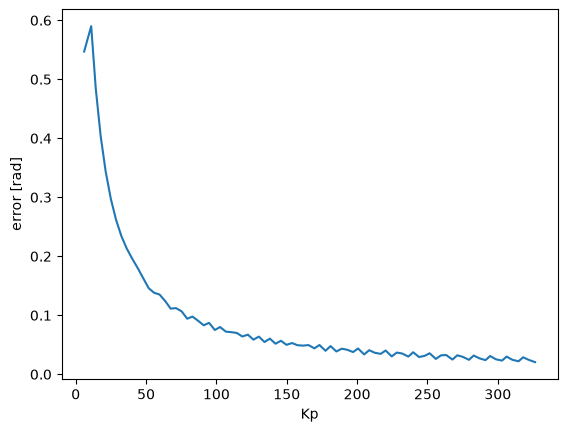

In [6]:
# plot development of error with Kp from the saved data
Kp_arr = pd.read_csv('ex1_data.csv')['Kp'].values
err_arr = pd.read_csv('ex1_data.csv')['error'].values
plt.plot(Kp_arr, err_arr)
plt.xlabel('Kp')
plt.ylabel('error [rad]')
plt.show() 

In [7]:
# ORIGINAL - test with aquired value for Kp

# Controller settings
q_desired = np.pi / 2    # target angle [rad]: arm horizontal
Kp = 326.0                 # proportional gain [N m per rad of error] #TODO: 
duration = 6.0#15.0           # how long to run [s]

# Start with the arm hanging down, at rest
ctl.reset_joints(pendulum, [motor], [0.0])

time_log, angle_log, torque_log = [], [], []
t = 0.0
while t < duration:
    # 1. SENSE: read the joint angle from the encoder
    q = p.getJointState(pendulum, motor)[0]

    # 2. CONTROL: compute the motor torque from the error
    error = q_desired - q
    torque = Kp * error

    # 3. ACT: send the torque to the motor, and let the simulated world move for one time step
    p.setJointMotorControl2(pendulum, motor, p.TORQUE_CONTROL, force=torque)

    
    # 4. WAIT: let one time step of real time pass, so what you see runs at real speed (comment out for faster simulation, or sleep for DT/4)
    p.stepSimulation()
    t = t + DT
    
    time.sleep(DT)

    # Logging:
    time_log.append(t)
    angle_log.append(q)
    torque_log.append(torque)

p_time, p_angle, p_torque = time_log, angle_log, torque_log   # keep this run, to compare later
ctl.plot_series(time_log, {"P": angle_log}, ylabel="angle [rad]", ref=q_desired)
ctl.plot_series(time_log, {"P": torque_log}, ylabel="torque [N m]")




In [8]:
# ORIGINAL - test with suboptimal value for Kp -> for comparison in future plots

# Controller settings
q_desired = np.pi / 2    # target angle [rad]: arm horizontal
Kp = 30.0#326.0                 # proportional gain [N m per rad of error] #TODO: 
duration = 6.0#15.0           # how long to run [s]

# Start with the arm hanging down, at rest
ctl.reset_joints(pendulum, [motor], [0.0])

time_log, angle_log, torque_log = [], [], []
t = 0.0
while t < duration:
    # 1. SENSE: read the joint angle from the encoder
    q = p.getJointState(pendulum, motor)[0]

    # 2. CONTROL: compute the motor torque from the error
    error = q_desired - q
    torque = Kp * error

    # 3. ACT: send the torque to the motor, and let the simulated world move for one time step
    p.setJointMotorControl2(pendulum, motor, p.TORQUE_CONTROL, force=torque)

    
    # 4. WAIT: let one time step of real time pass, so what you see runs at real speed (comment out for faster simulation, or sleep for DT/4)
    p.stepSimulation()
    t = t + DT
    
    time.sleep(DT)

    # Logging:
    time_log.append(t)
    angle_log.append(q)
    torque_log.append(torque)

p_time, p_angle, p_torque = time_log, angle_log, torque_log   # keep this run, to compare later
ctl.plot_series(time_log, {"P": angle_log}, ylabel="angle [rad]", ref=q_desired)
ctl.plot_series(time_log, {"P": torque_log}, ylabel="torque [N m]")




> **Q1.** The arm stops below the target. When it is at rest, which two torques must balance? Use that to explain the remaining error, and what happens to it if you increase $K_p$.

**Answer Q1.**:  
The introduced torque must balance the "gravitational torque" (which is caused by the tangential component of the gravitational force). 
With this proportionality approach there will be a value where the externally introduced torque $\tau_{ext}$ = Kp * error balances the gravitational torque, i.e. $\tau_g$ = $\tau_{ext}$. Since an equilibrium is reached no further motion will appear. This will lead to a stagnation of the error and with that to a stagnation of the torque calculated by the controller. A steady-state-error remains.\\

If we increase Kp, we can lower this remaining error, but we can never completely get rid of it.

### 1.2 PID control

Two more terms, both computed from the error:

- **integral**: the sum of all past errors, each multiplied by the time step;
- **derivative**: how fast the error is changing, from the difference between this error and the previous one.

$$\tau = K_p\, e_k + K_i \sum_{j \le k} e_j\,\Delta t + K_d\, \frac{e_k - e_{k-1}}{\Delta t}$$

> **T2.** Implement the PID control law, then run the cell with $K_i = 0$ first (PD), then with $K_i \neq 0$ (PID). 

In [9]:
# define PID gains for the PID controller
# note that booleans of set1 & set2 must be set to False if you want to use your own values for Kp, Ki, Kd
Kp = 326.0 
Ki = 20.0 
Kd = 100.0


# ----------------------------------------------
# use booleans if you want to use predefined sets.
set1 = False  # working set of parameters: [Kp=326.0, Ki=20.0, Kd=100.0]
set2 = True   # working set of parameters: [Kp=30.0, Ki=19.0, Kd=7.0]

if set1: 
    Kp = 326.0 
    Ki = 20.0 
    Kd = 100.0

if set2: 
    Kp = 30.0 
    Ki = 19.0 
    Kd = 7.0

else: 
    pass
# ----------------------------------------------

duration = 6.0

ctl.reset_joints(pendulum, [motor], [0.0])

error_sum = 0.0                  # for the integral term
error_previous = q_desired - 0.0 # for the derivative term (error at the start)

time_log, angle_log, torque_log = [], [], []
t = 0.0

while t < duration:
    # 1. SENSE
    q = p.getJointState(pendulum, motor)[0]

    # 2. CONTROL
    error = q_desired - q
    error_sum += error*DT
    error_rate = (error - error_previous)/DT
    
    torque = Kp*error + Ki*error_sum + Kd*error_rate

    error_previous = error #save for next iteration
    
    # 3. ACT
    p.setJointMotorControl2(pendulum, motor, p.TORQUE_CONTROL, force=torque)
    p.stepSimulation()
    t = t + DT

    # 4. WAIT
    #time.sleep(DT)

    time_log.append(t)
    angle_log.append(q)
    torque_log.append(torque)

label = f"Kp={Kp}, Ki={Ki}, Kd={Kd}"
ctl.plot_series(time_log, {"P": p_angle, label: angle_log}, ylabel="angle [rad]", ref=q_desired)
ctl.plot_series(time_log, {"P": p_torque, label: torque_log}, ylabel="torque [N m]")

# plot without P for comparison
#ctl.plot_series(time_log, {label: angle_log}, ylabel="angle [rad]", ref=q_desired)
#ctl.plot_series(time_log, {label: torque_log}, ylabel="torque [N m]")


**Q2.** What does each term change in the response: overshoot, time to settle, final error? Why does the integral term remove the final error, and what does it cost?

**Q3.** What happens to the torque when $K_d$ is very large? Look at the torque plot.

**Answer Q2.**  
- $K_p$ sets the "basic zero" line around which the oscillation will occur. As discussed above, this line (which corresponds to the remaining error) can never reach the target value, although higher $K_p$ values will lead to smaller rest-errors.

- $K_i$ takes past errors into account. That means that even if a steady-state situation has been reached due to the limits of $K_p$: if a non-zero error exists, $K_i$ will keep changing and thereby alter the applied torque to reach the target_value _until the target value has been reached_.  
Since $K_i$ takes into account a wide range of past errors (in our case even the entire range), it shows some kind of inertia, i.e. it can not stop changing $\tau$ immediately as soon as the target value has been reached, but it will overshoot. Since the overshooting causes a change of sign in the error, the summ will become negative at some point leading to the counter-movement of the oscillation. The "inertia" will occur in this direction as well.

- $K_p$ helps to reduce the overshooting. By taking the derivative, the rate of change of the error is being calculated. F.ex. a strongly decreasing error (which can occur when the target is approached very fast), leads to a large negative rate of change - which will be deducted from the estimation for the new $\tau$ value, counterbalancing a potential overshoot caused by the $K_i$-term. This means, $K_p$ has a dampening effect and prolonges the time it takes to settle.

**Answer Q3.**  
When $K_d$ is large, the torque rapidly gets dampened - exhibiting one characteristic bump in the graph, which gets very steep for large values ("derivative kick").
After this initial damping for f.ex. $K_d=200$ the torque changes very slowly which leads to a very slow but steady approach of the target value.  
When $K_d$ is _very_ large (f.ex. $K_d=300$ or in the simulation visible at $K_d=600$), the torque exhibits oscillations in the beginning. At $K_d=300$ it is able to stabilize at some point; at $K_d=600$ it gets trapped in this rapidly oscillating state. This phenomenon is most probably caused due to the derivative kick in combination with numerical instabilities. 

Let's implement the reusable `PID` class

In [10]:
class PID:
    def __init__(self, Kp, Ki, Kd, dt):
        self.Kp, self.Ki, self.Kd, self.dt = Kp, Ki, Kd, dt
        self.clear()
        
    def clear(self):
        self.error_sum = 0.0
        self.error_previous = None        # no derivative kick on the first step

    def step(self, error):
        if self.error_previous is None:
            self.error_previous = error
        
        #TODO: - DONE
        self.error_sum += error*self.dt
        error_rate = (error - self.error_previous)/self.dt
        control = self.Kp*error + self.Ki*self.error_sum + self.Kd*error_rate

        self.error_previous = error
        return control

### 1.3 A heavy payload, and gravity compensation

The torque that gravity applies on the pendulum depends on the angle and on the masses:

$$\tau_{gravity}(q) = g\,\left(m_{arm}\,\frac{L}{2} + m_{ball}\,L\right)\sin q$$

Helper functions `get_length()`and `get_mass()` give us the robot parameters.

**T3.** write this function, and compare it with the torque PyBullet computes to hold the pendulum still at a few angles. 

In [11]:
L = ctl.get_length(pendulum,"ball_link")
m_ball = ctl.get_mass(pendulum,"ball_link")
m_arm = ctl.get_mass(pendulum,"arm_link")

def gravity_torque(q, m_ball):
    #TODO: - DONE
    gravity = 9.81 * (m_arm *L/2 + m_ball * L) * np.sin(q)
    return gravity

for q in [0.3, 1.2, 2.5]:
    pybullet_torque = p.calculateInverseDynamics(pendulum, [q], [0.0], [0.0])[0]
    ctl.check(f"q = {q} rad", gravity_torque(q, m_ball), pybullet_torque)

[PASS] q = 0.3 rad: got [2.325], expected [2.325], error 2.49e-07
[PASS] q = 1.2 rad: got [7.3329], expected [7.3329], error 2.27e-07
[PASS] q = 2.5 rad: got [4.7086], expected [4.7086], error 7.22e-08


Now the pendulum carries 10 kg. Run your PID again, with the same gains.

In [13]:
ctl.change_mass(pendulum, "ball_link", 10.0)

#TODO: - DONE
pid = PID(Kp=30.0, Ki=19.0, Kd=7.0, dt=DT)   # same gains as before, new controller (empty integral)
duration = 10.0

ctl.reset_joints(pendulum, [motor], [0.0])

time_log, angle_log = [], []
t = 0.0
while t < duration:
    q = p.getJointState(pendulum, motor)[0]

    torque = pid.step(q_desired - q)

    p.setJointMotorControl2(pendulum, motor, p.TORQUE_CONTROL, force=torque)
    p.stepSimulation()
    t = t + DT
    time.sleep(DT/10)

    time_log.append(t)
    angle_log.append(q)

heavy_time, heavy_angle = time_log, angle_log
ctl.plot_series(time_log, {"PID, 10 kg": angle_log}, ylabel="angle [rad]", ref=q_desired)

If we know the gravity torque, we can add it to the command. Then the PID only has to correct what the model gets wrong.

$$\tau = \tau_{PID} + \tau_{gravity}(q)$$

In [14]:
#m_ball_model = 10.0
#pid = PID(Kp=300.0, Ki=150.0, Kd=30.0, dt=DT)

m_ball_model = 8.0
pid = PID(Kp=300.0, Ki=150.0, Kd=30.0, dt=DT)

ctl.reset_joints(pendulum, [motor], [0.0])

time_log, gc_angle = [], []
t = 0.0
while t < duration:
    q = p.getJointState(pendulum, motor)[0]

    torque = pid.step(q_desired - q) + gravity_torque(q, m_ball_model)   # feedback + model
    #torque =  gravity_torque(q, m_ball_model)   # test gravity only


    p.setJointMotorControl2(pendulum, motor, p.TORQUE_CONTROL, force=torque)
    p.stepSimulation()
    t = t + DT
    time.sleep(DT)

    time_log.append(t)
    gc_angle.append(q)

ctl.plot_series(time_log, {"PID": heavy_angle, f"PID + gravity (model: {m_ball_model} kg)": gc_angle},
                ylabel="angle [rad]", ref=q_desired)

**Q4.** Why does the plain PID struggle with 10 kg, when the same gains worked with 2 kg?

**T4.** Set `m_ball_model = 8.0` (the model is wrong) and run again, first with `Ki = 0` and then with the original `Ki`. Explain what you see.

**Answer Q4.**:  
Because the gains have been optimized for 2 kg. Especially $K_p$ sets the general base line which will be further optimized by $K_i$ and $K_p$. If this base line is too low, the controller will struggle. And it is too low since it was chosen in such a way that the steady-state error would be minimized. The steady-state error represents the moment where $F_{g ~tangential} = F_{external ~torque}$ and $F_{g ~tangential}$ depends on the mass of our object. This means that if we optimize our controlling output $F_{external ~torque}$ for a certain mass, it will not match a heavier one.

**Answer T4.**:
- For $K_i=0$, the angle stabilized rather quickly, but at an angle above our target value. It is the same situation as discussed in Q1 where $K_p$ leads to an unavoidable steady-state error. The only difference here is, that this remaining error is positive due to the additionally added gravity torque from the model. 

- For $K_i=150$, we see an initial overshoot to the same level as in the $K_i=0$ situation. But now, the non-zero integral gain $K_i$ sums the error and deducts it from the steady-state which is why we can see a convergence towards the target value. The speed of the convergence as well as the magnitude of the initial spike could be optimized.

## 2. A 2-link arm

Now we have two joints, `shoulder_joint` and `elbow_joint`, with a payload at the tip.
The tip must go around a **triangle** in the plane of the arm.

The controller works on the joints, so first we turn the path of the tip into a path of the joints:

1. the desired tip position at every time step (`ctl.create_triangle_traj`);
2. inverse kinematics at every time step, each search starting from the previous solution;
3. joint velocities and accelerations, by differentiating the joint path.

In [15]:
ctl.connect(camera_target=(0.5, -0.3, 1.0), camera_distance=2.5)
arm = ctl.load_robot("arm_2r.urdf")
arm_joints, joint_names = ctl.moving_joints(arm)
arm_tip = ctl.link_index(arm, "tip_link")

# 1. Desired tip positions: two laps of 4 s around a triangle in the plane of the arm (y = -0.35 m)
corners = [[0.5, -0.35, 1.0], [0.9, -0.35, 1.0], [0.7, -0.35, 1.5]]
times, tip_desired = ctl.create_triangle_traj(corners, lap_time=4.0, laps=2)

In [17]:
# 2. Inverse kinematics. We start the search from the previous solution before each call.
q_guess = [1.0, 1.0]
q_path = []
for position in tip_desired:
    ctl.reset_joints(arm, arm_joints, q_guess)
    q_guess = p.calculateInverseKinematics(arm, arm_tip, list(position))
    q_path.append(q_guess)
q_path = np.array(q_path)

# 3. Joint velocities and accelerations
qd_path = np.gradient(q_path, DT, axis=0)
qdd_path = np.gradient(qd_path, DT, axis=0)

ctl.draw_polyline(corners + corners[:1], color=(0, 0, 0))
ctl.plot_joints(times, {"desired": q_path}, joint_names=joint_names)

_Note to ourselves: this means - here we have calculated out target positions for the entire path.  
In the next step, we want the 2 link robot to meet these positions._

### 2.1 PID on each joint

The same PID as for the pendulum, now with one error per joint (NumPy arrays instead of numbers).
We also record where the tip goes.

In [18]:
# The same PID class, with one gain per joint
pid = PID(Kp=np.array([400.0, 150.0]), Ki=np.array([100.0, 50.0]), Kd=np.array([40.0, 12.0]), dt=DT)

ctl.reset_joints(arm, arm_joints, q_path[0])

angle_log, torque_log, tip_log = [], [], []
for k in range(len(times)):
    states = p.getJointStates(arm, arm_joints)
    q = np.array([states[0][0], states[1][0]])

    torque = pid.step(q_path[k] - q) # reminder: pid.step takes the error as argument

    p.setJointMotorControlArray(arm, arm_joints, p.TORQUE_CONTROL, forces=list(torque))
    p.stepSimulation()
    time.sleep(DT)

    angle_log.append(q)
    torque_log.append(torque)
    tip_log.append(p.getLinkState(arm, arm_tip)[4])

pid_angle, pid_torque, pid_tip = np.array(angle_log), np.array(torque_log), np.array(tip_log)
ctl.draw_polyline(pid_tip, color=(0, 0, 1), every=10)
ctl.plot_joints(times, {"PID": pid_angle}, ref=q_path, joint_names=joint_names)

For two joints, the equation of motion is a matrix equation:

$$M(q)\,\ddot q + C(q,\dot q)\,\dot q + g(q) = \tau$$

$M(q)$, the inertia matrix, changes with the configuration. Look at it with the elbow stretched and folded:

In [19]:
for elbow in [0.0, np.pi / 2, 2.5]: # 2.5 rad ~ 143 degrees
    M = p.calculateMassMatrix(arm, [np.pi / 2, elbow])
    print(f"elbow at {elbow:.2f} rad:\n{np.array(M)}\n")

elbow at 0.00 rad:
[[5.788073 2.306273]
 [2.306273 1.046273]]

elbow at 1.57 rad:
[[3.268073 1.046273]
 [1.046273 1.046273]]

elbow at 2.50 rad:
[[1.24919109 0.03683204]
 [0.03683204 1.046273  ]]



_Note to ourselves:  
0.00 rad means - no angle of second link in reference to first link, i.e. arm is fully stretched.  
2.50 rad means - arm is strongly folded._

**Q6.** Where along the triangle is the PID error largest? Use $M(q)$ to explain why the same gains do not work equally well in every configuration.

**Q7.** At the corners the tip must change direction instantly. What does that mean for the joint accelerations? Plot `qdd_path`.

**Answer Q6.**:  
The error is largest for the bottom trajectory where the arm is more stretched than on the other trajectory parts. If we look at $M(q)$, we see, that we have large values in the off-diagonal elements for 0.0 rad (fully stretched) and almost zero values for the 2.5 rad scenario (strongly folded). 

Looking at our matrix equation...  
_(eq. made by ChatGPT)_

$$
\begin{bmatrix}
\tau_1 \\
\tau_2
\end{bmatrix}
=
\begin{bmatrix}
M_{11} & M_{12} \\
M_{21} & M_{22}
\end{bmatrix}
\begin{bmatrix}
\ddot{q}_1 \\
\ddot{q}_2
\end{bmatrix}
$$

... we can understand, that large off-diagonal elements correspond to coupled torque equations while for zero-diagonal elements $\tau_1$ and $\tau_2$ would be independent of each other. Since our pid-controller expects these two values to be independent, it seems reasonable, that larger errors occur for the path-segments where this assumption is wrong (i.e. the bottom path).

**Answer Q7.**:

An instantaneous change of direction implies an instantaneous change of velocity. 
Since the acceleration is the velocity's derivative, for large values of velocity changes $\Delta \vec{v}$ (much larger than infinitesimal changes of the usual derivative $d\vec{v}$) we would expect something like: 

\begin{align}
\frac{\Delta\vec{v}}{dt} = \frac{\Delta\vec{v}}{\rightarrow 0} = \rightarrow \infty
\end{align}

This means theoretically we would expect extremities/poles. In reality they manifest as spikes in the acceleration plot (as seen below). 

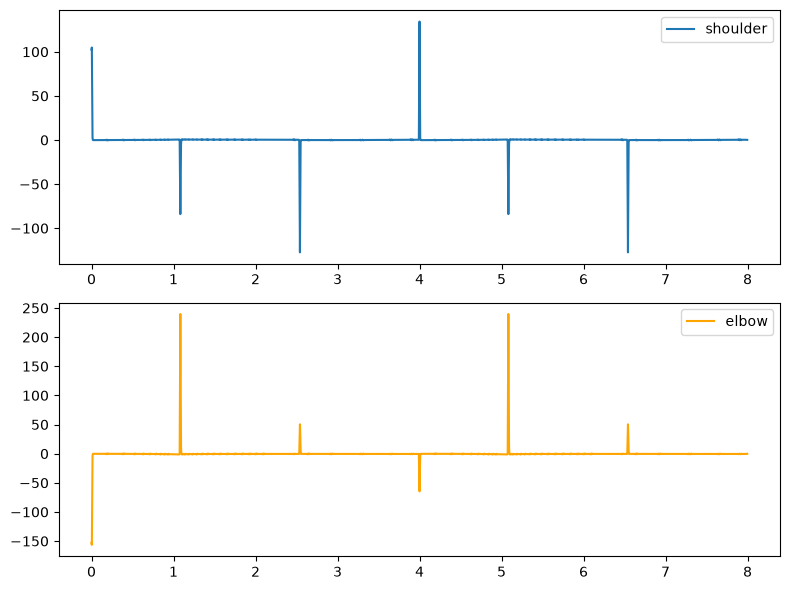

In [20]:
# plot qdd
fig, axes = plt.subplots(2, 1, figsize=(8, 6))

axes[0].plot(times, qdd_path[:, 0], label="shoulder")
axes[0].legend()

axes[1].plot(times, qdd_path[:, 1], label="elbow", color='orange')
axes[1].legend()

plt.tight_layout()

### 2.2 Computed torque

Instead of a torque, we choose the **acceleration** we want each joint to have, and ask the model which torque produces it:

$$\ddot q_{command} = \ddot q_{desired} + K_d\,(\dot q_{desired} - \dot q) + K_p\,(q_{desired} - q)$$

$$\tau = M(q)\,\ddot q_{command} + C(q,\dot q)\,\dot q + g(q)$$

PyBullet computes the second line for us: `p.calculateInverseDynamics(robot, q, qd, qdd_command)`.
If the model is exact, the error of each joint behaves like a mass-spring-damper, $\ddot e + K_d\,\dot e + K_p\,e = 0$, in every configuration. We choose its natural frequency $\omega_n$ and damping ratio $\zeta$: $K_p = \omega_n^2$, $K_d = 2\zeta\omega_n$.

The controller needs the joint velocities, so we need to read them too.

In [21]:
wn = 10.0     # natural frequency of the error [rad/s]
zeta = 1.0    # damping ratio
Kp = wn ** 2
Kd = 2 * zeta * wn

ctl.reset_joints(arm, arm_joints, q_path[0])

angle_log, torque_log, tip_log = [], [], []
for k in range(len(times)):
    states = p.getJointStates(arm, arm_joints)
    q = np.array([states[0][0], states[1][0]])
    qd = np.array([states[0][1], states[1][1]])

    qdd_command = qdd_path[k] + Kd * (qd_path[k] - qd) + Kp * (q_path[k] - q)
    torque = p.calculateInverseDynamics(arm, list(q), list(qd), list(qdd_command))

    p.setJointMotorControlArray(arm, arm_joints, p.TORQUE_CONTROL, forces=list(torque))
    p.stepSimulation()
    time.sleep(DT)

    angle_log.append(q)
    torque_log.append(torque)
    tip_log.append(p.getLinkState(arm, arm_tip)[4])

ct_angle, ct_torque, ct_tip = np.array(angle_log), np.array(torque_log), np.array(tip_log)

In [22]:
ctl.draw_polyline(ct_tip, color=(1, 0, 0), every=10)

ctl.plot_joints(times, {"PID": pid_angle, "computed torque":  ct_angle},
                joint_names=joint_names, ylabel="angle [rad]", ref=q_path)

ctl.plot_path2d({"PID": pid_tip, "computed torque": ct_tip}, ref=tip_desired)
ctl.plot_joints(times, {"PID": q_path - pid_angle, "computed torque": q_path - ct_angle},
                joint_names=joint_names, ylabel="error [rad]")
ctl.plot_joints(times, {"PID": pid_torque, "computed torque": ct_torque},
                joint_names=joint_names, ylabel="torque [N m]")

**Q8.** Where does computed torque still make an error? Think about the corners, and about what the model ignores (look at `<dynamics>` in `arm_2r.urdf`).

**Q9.** Try other values of $\omega_n$ and $\zeta$. What would limit $\omega_n$ on a real robot?

**Answer Q8.** 

The corners are where the computed torque still makes errors, because these are areas where the velocity profile undergoes an abrupt change in direction. Theoretically, this would mean an instantaneous and infinite acceleration, which the robot can't do on its timestep DT.   

Looking at the `<dynamics>` tags in the `arm_2r.urdf` file, the joints have both viscous damping (damping="0.5") and Coulomb friction (friction="0.2") mapped into the simulator. Computed torque still makes an error here because PyBullet's `p.calculateInverseDynamics` function only computes the ideal rigid-body dynamics, ignoring these friction parameters.


**Answer Q9.** 

Increasing $\omega_n$ increases controller stiffness (K_p = $\omega_n^2$), making the robot track the triangle much tighter, though setting it too high causes oscillations. Decreasing $\omega_n$ makes the tracking sluggish, rounding off the corners.

Keeping $\zeta$ (critical damping) is ideal because it gives the fastest response without overshoot. Setting $\zeta$ < 1.0 introduces oscillations after the corners, while $\zeta$> 1.0 slows the system down too much.

In a real robot, it's imposible to increase $\omega_n$ indefinetely, due to several physical constraints, like limit of torque a motor could deliver due to voltage and current limits; or the fact that high gains would increase the vibrations on the robot and make it shake and be very noisy.

## 3. Franka FR3: bringing kinematics and control together

The same steps on a 7-joint robot. The tool tip must follow a **descending helix** (two turns) that starts where the tip is, keeping the tool pointing down.

In [34]:
ctl.connect(camera_target=(0.5, 0, 0.35), camera_distance=1.6, yaw=50, pitch=-25)
panda = ctl.load_robot("franka_panda/panda.urdf")
panda_joints, panda_joint_names = ctl.moving_joints(panda)   # 7 arm joints + 2 fingers
tip = ctl.link_index(panda, "panda_grasptarget")

# Initial configuration, tool pointing down
q_home = [0.0, -0.3, 0.0, -2.2, 0.0, 1.9, 0.785, 0.02, 0.02]
ctl.reset_joints(panda, panda_joints, q_home)
tip_state = p.getLinkState(panda, tip, computeForwardKinematics=True)
tip_start = tip_state[4]         # position [m]
tip_orientation = tip_state[5]   # orientation (quaternion), kept constant along the path

# 1. Desired tip positions: a helix starting at the tip, radius 0.1 m, going down 0.25 m in 6 s
times, tip_desired = ctl.create_3d_helix(tip_start, radius=0.1, depth=0.25, turns=2, duration=6.0)

# 2. Inverse kinematics, each search starting from the previous solution
q_guess = q_home
q_path = []
for position in tip_desired:
    ctl.reset_joints(panda, panda_joints, q_guess)
    q_guess = p.calculateInverseKinematics(panda, tip, list(position), tip_orientation)
    q_path.append(q_guess)
q_path = np.array(q_path)

# 3. Joint velocities and accelerations
qd_path = np.gradient(q_path, DT, axis=0)
qdd_path = np.gradient(qd_path, DT, axis=0)

ctl.draw_polyline(tip_desired, every=10)

**PD + gravity compensation**: $\tau = K_p\,(q_{desired} - q) + K_d\,(\dot q_{desired} - \dot q) + g(q)$, where $g(q)$ is inverse dynamics with zero velocity and acceleration.

In [35]:
Kp, Kd = 300.0, 30.0
zeros = [0.0] * len(panda_joints)

ctl.reset_joints(panda, panda_joints, q_path[0])
pd_tip = []
for k in range(len(times)):
    states = p.getJointStates(panda, panda_joints)
    q = np.array([state[0] for state in states])
    qd = np.array([state[1] for state in states])

    gravity = np.array(p.calculateInverseDynamics(panda, list(q), zeros, zeros))
    torque = Kp * (q_path[k] - q) + Kd * (qd_path[k] - qd) + gravity

    p.setJointMotorControlArray(panda, panda_joints, p.TORQUE_CONTROL, forces=list(torque))
    p.stepSimulation()
    time.sleep(DT)

    pd_tip.append(p.getLinkState(panda, tip)[4])

pd_tip = np.array(pd_tip)
ctl.draw_polyline(pd_tip, color=(0, 0, 1), every=10)

**Computed torque**, exactly as for the 2-link arm.

In [36]:
wn, zeta = 20.0, 1.0
Kp, Kd = wn ** 2, 2 * zeta * wn

ctl.reset_joints(panda, panda_joints, q_path[0])
ct_tip = []
for k in range(len(times)):
    states = p.getJointStates(panda, panda_joints)
    q = np.array([state[0] for state in states])
    qd = np.array([state[1] for state in states])

    qdd_command = qdd_path[k] + Kd * (qd_path[k] - qd) + Kp * (q_path[k] - q)
    torque = p.calculateInverseDynamics(panda, list(q), list(qd), list(qdd_command))

    p.setJointMotorControlArray(panda, panda_joints, p.TORQUE_CONTROL, forces=list(torque))
    p.stepSimulation()
    time.sleep(DT)

    ct_tip.append(p.getLinkState(panda, tip)[4])

ct_tip = np.array(ct_tip)
ctl.draw_polyline(ct_tip, color=(1, 0, 0), every=10)

In [37]:
ctl.plot_path3d({"PD + gravity": pd_tip, "computed torque": ct_tip}, ref=tip_desired)

pd_error = 1000 * np.linalg.norm(pd_tip - tip_desired, axis=1)   # [mm]
ct_error = 1000 * np.linalg.norm(ct_tip - tip_desired, axis=1)
ctl.plot_series(times, {"PD + gravity": pd_error, "computed torque": ct_error}, ylabel="tip error [mm]")

**Q10.** Where along the helix is the PD error largest, and why there?

**Q11.** Make the helix twice as fast (`duration=3.0`). Which controller suffers more, and why?

**Answer Q10.**: 
The PD controller shows its largest tracking error around 3.3 seconds, during the middle portion of the helical trajectory, reaching approximately 8.9 mm.

This happens because the PD controller compensates for gravity but does not explicitly account for the robot's inertial and Coriolis effects. As the robot follows the helix, the joints must continuously change their velocities and accelerations, making it harder for the controller to accurately track the desired trajectory.

In comparison, the computed torque controller achieves much smaller errors because it accounts for the robot's dynamics.

**Answer Q11.**:

When the duration is reduced from 6 to 3 seconds, the PD + gravity controller suffers significantly more than the computed torque controller. The maximum tracking error increases from approximately 9 mm to 37 mm for the PD controller, while the computed torque controller maintains a much smaller error.

This happens because the faster trajectory requires higher joint velocities and accelerations. The PD controller compensates for gravity but does not explicitly account for the robot's inertial and Coriolis effects, making it harder to follow the desired trajectory accurately.

In contrast, the computed torque controller uses the robot's dynamic model to compensate for these effects, allowing it to maintain better tracking accuracy even at higher speeds.

In [ ]:
p.disconnect()